## Time Windows and One Courier’s Route Execution (Flag 10)

### Dataset Overview
A one-courier case with five daily task sets. It provides delivery event times, optional explicit service windows, network-shortest route distance, realized route distance, and task-linked GPS segments. 59 of 90 tasks (65.6%) have no time window.

The notebook exposes a primary table and a supporting table (`courier_trajectories.csv`).

Goal: Analyze how time windows affect the delivery behavior of the same courier using the supplied trajectories.

Role: Last-mile delivery operations analyst


Category: time-window constraints, network-route efficiency, and delivery speed

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_tasks.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does route detour relative to the supplied network-shortest distance vary with promised service-window width?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

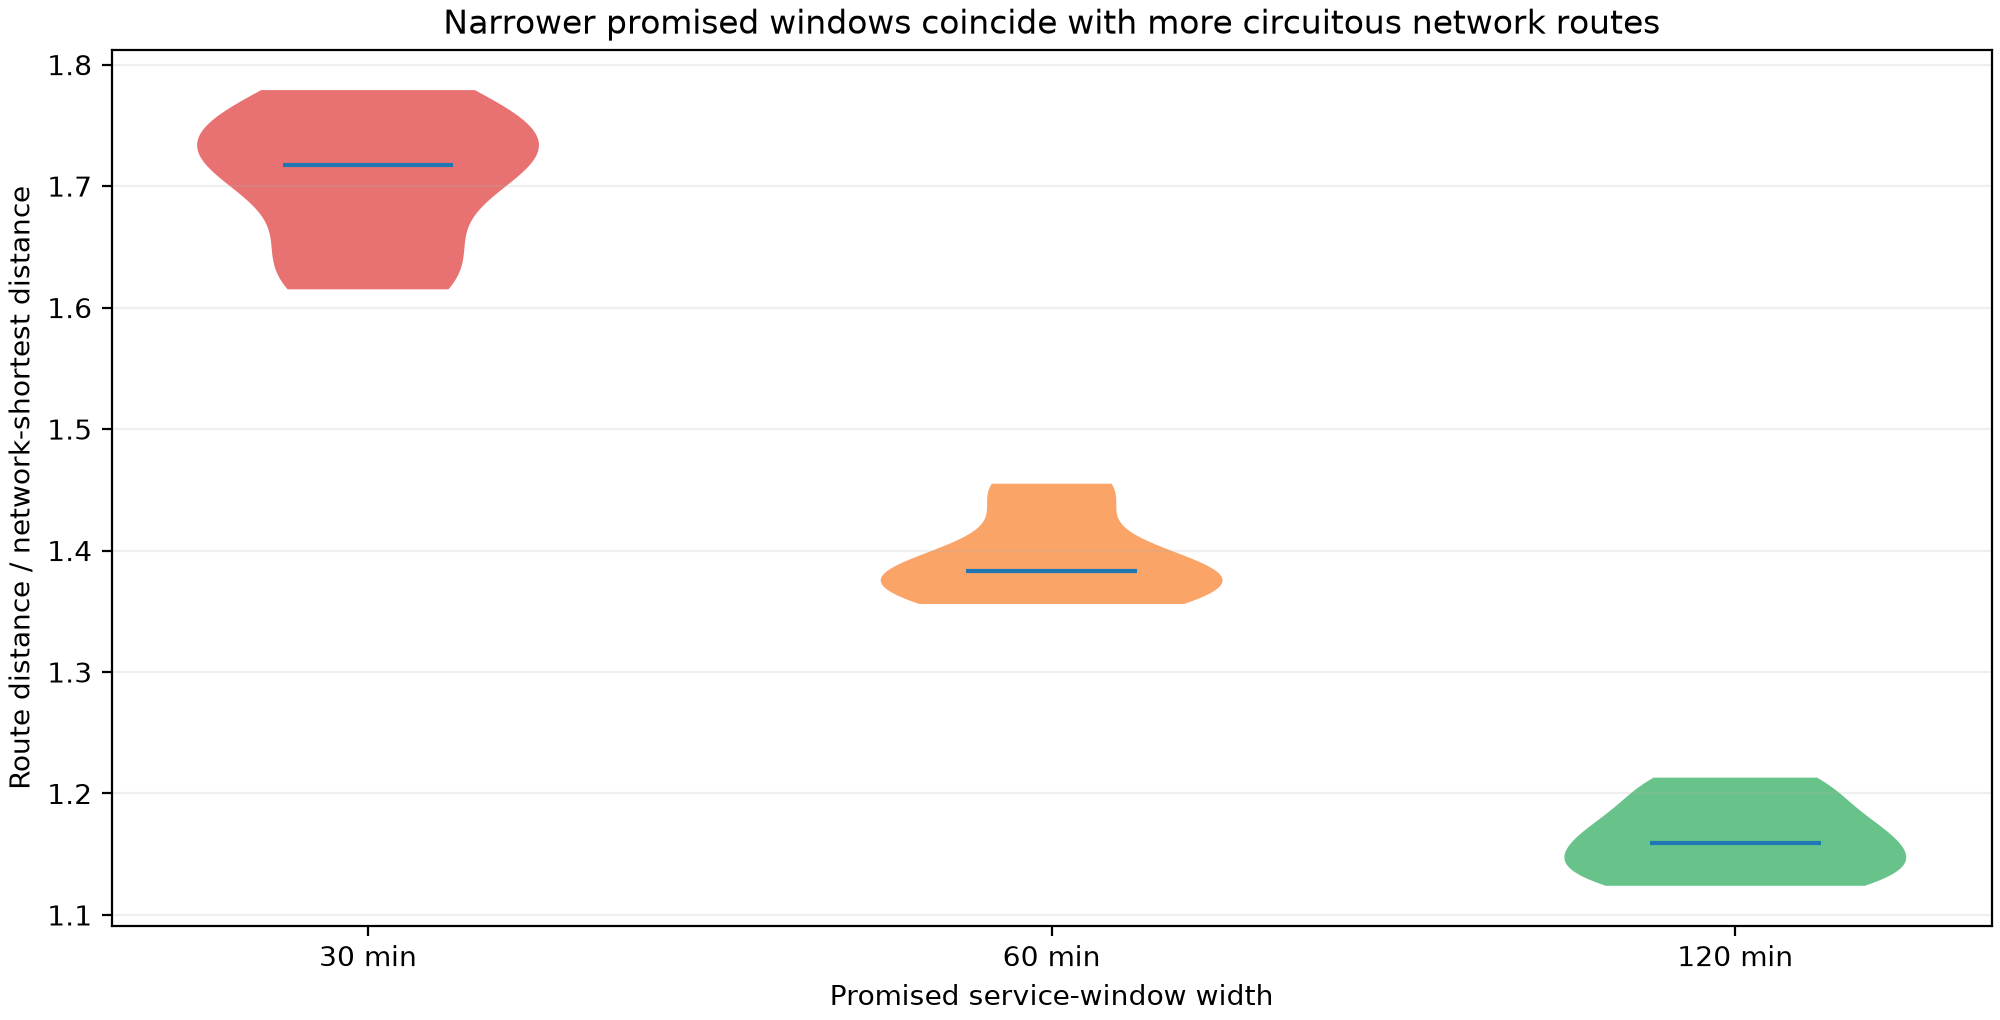

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/window_width_detour_ratio.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "window_width_network_detour",
  "insight": "Narrower promised service windows are associated with higher route detour ratios, indicating more circuitous delivery paths relative to the supplied network-shortest distance.",
  "plot": {
    "plot_type": "window_width_detour_violin",
    "title": "Time-Window Width and Route Detour",
    "file": "visualizations/window_width_detour_ratio.png",
    "description": "The full route-detour-ratio distributions show increasingly circuitous paths as constrained windows narrow."
  },
  "question": "How does route detour relative to the supplied network-shortest distance vary with promised service-window width?",
  "insight_type": "factor_relationship",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "time_window_start",
    "time_window_end",
    "delivery_time",
    "network_shortest_route_distance",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 2**: How do daily route efficiency and speed change as the share of the courier’s tasks with promised time windows increases?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

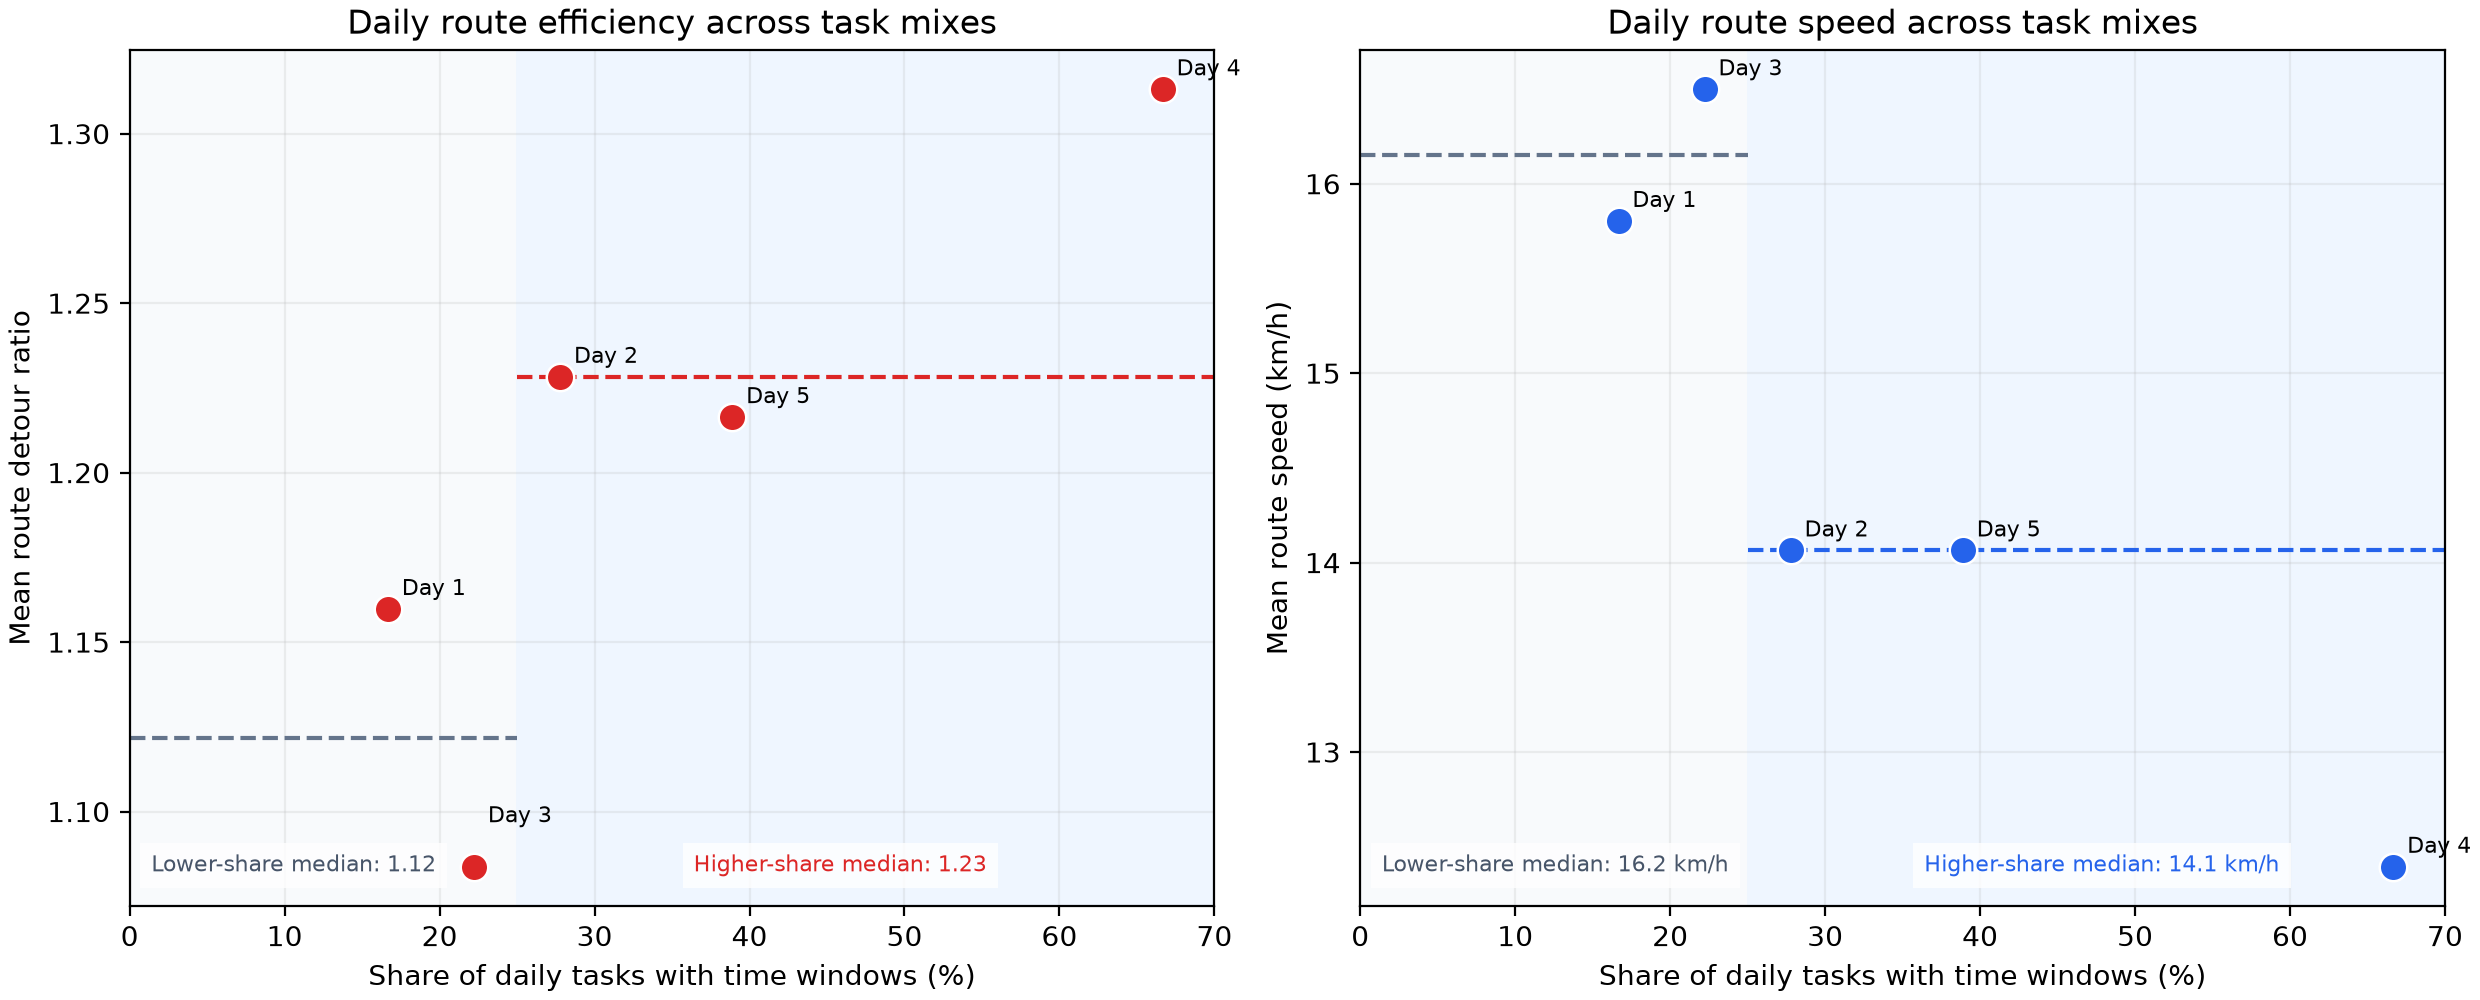

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/daily_time_window_share_efficiency_speed.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "daily_time_window_share_route_execution",
  "insight": "On days when this courier handles a larger share of time-window-constrained tasks, route execution is less efficient and average travel speed is lower than on days dominated by unconstrained tasks.",
  "plot": {
    "plot_type": "daily_share_efficiency_speed_scatter",
    "title": "Daily Time-Window Share, Route Efficiency, and Speed",
    "file": "visualizations/daily_time_window_share_efficiency_speed.png",
    "description": "Each point is one daily task set; more than 60% of all supplied tasks have no time window."
  },
  "question": "How do daily route efficiency and speed change as the share of the courier’s tasks with promised time windows increases?",
  "insight_type": "factor_relationship",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "time_window_start",
    "time_window_end",
    "delivery_time",
    "network_shortest_route_distance",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 3**: After the main concentration of time-window-constrained tasks, how many further non-block tasks are accepted later in the day?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

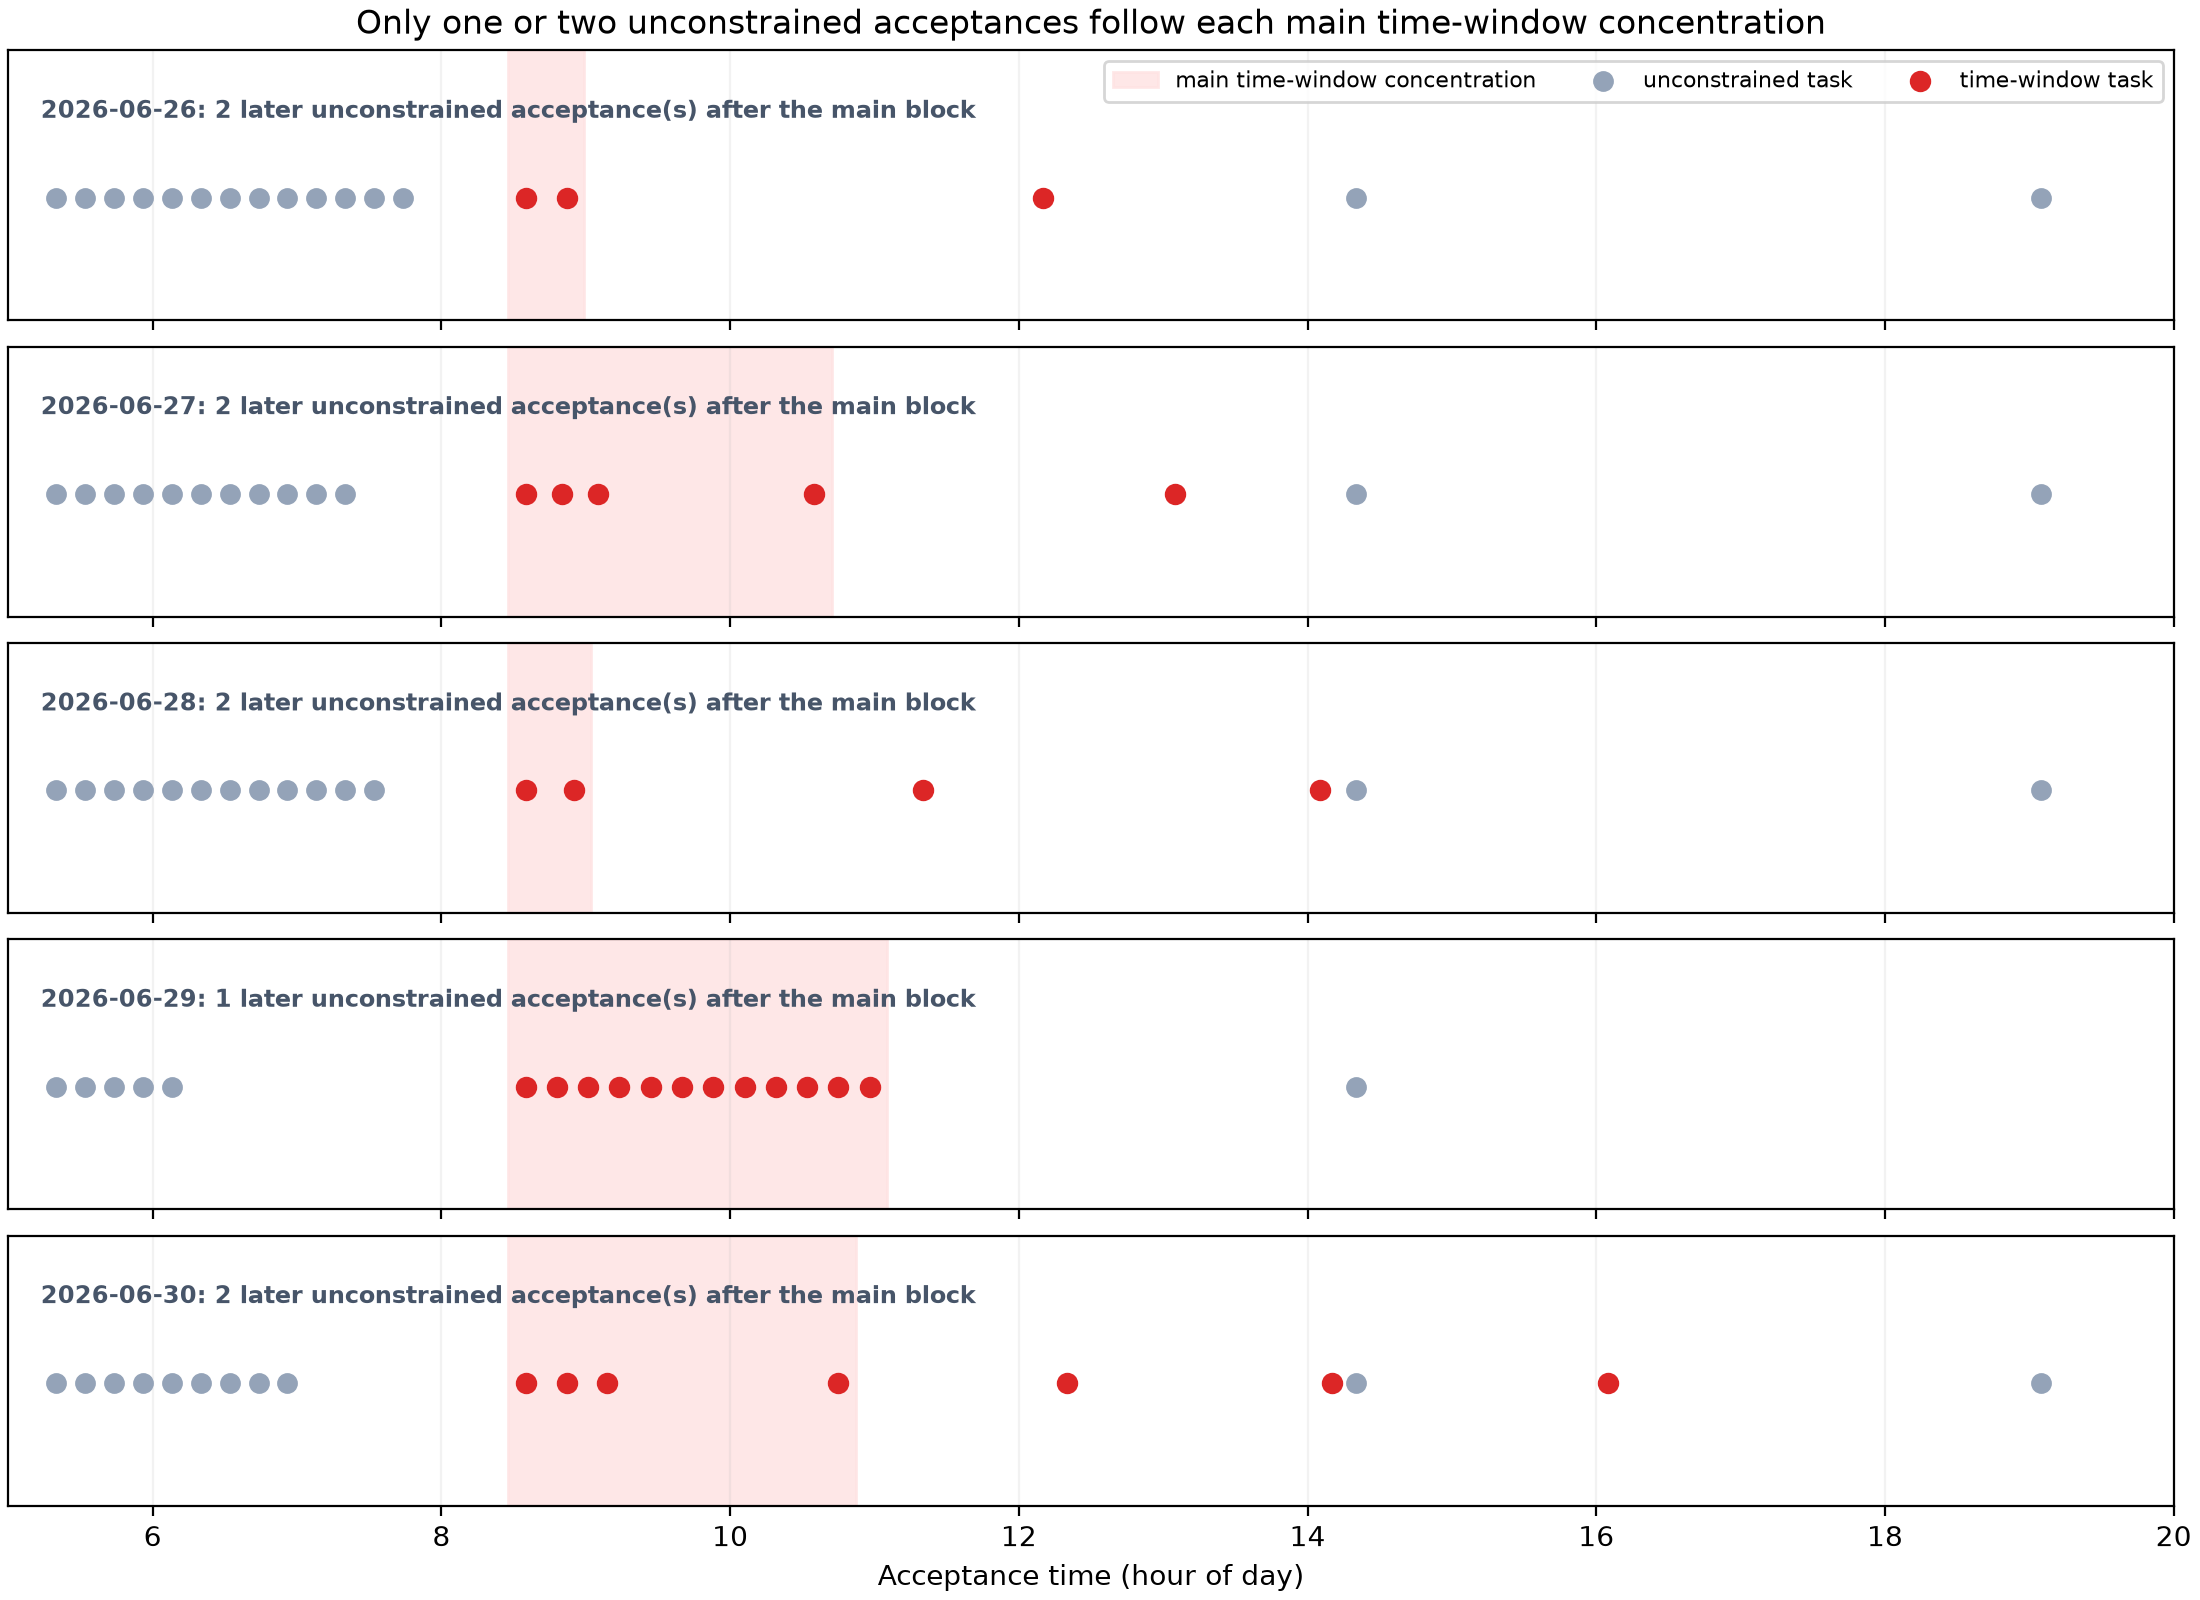

In [ ]:

# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/post_window_block_acceptance_drop.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "post_window_block_task_acceptance",
  "insight": "After the main concentration of time-window-constrained tasks, the courier's remaining acceptances become sparse.",
  "plot": {
    "plot_type": "daily_acceptance_timeline",
    "title": "Sparse Acceptance after the Main Time-Window Task Concentration",
    "file": "visualizations/post_window_block_acceptance_drop.png",
    "description": "Daily acceptance timelines distinguish the main constrained-task concentration, occasional later constrained tasks, and the sparse remaining acceptances."
  },
  "question": "After the main concentration of time-window-constrained tasks, how many further non-block tasks are accepted later in the day?",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### Summary of Findings (Flag 10)

For this courier, tighter time windows are associated with more circuitous routes and slower delivery execution. Daily task sets containing more constrained tasks show poorer route efficiency, while acceptance becomes sparse after each day’s main concentration of constrained tasks.